# Pairs trading: statistics, machine learning, and an honest backtest

This notebook builds a two-asset spread, trades deviations from its recent mean,
and evaluates whether a machine-learning entry filter helps on held-out data.
**The default dataset is synthetic, not actual market prices.** It deliberately
contains related assets, so favorable demo results do not establish a real edge.

Run all cells in order. Change the configuration to load CSV files or optional
Yahoo Finance data. No broker connection or order submission is included.

We proceed through data collection, pair selection, spread modeling, baseline
trading, ML, and out-of-sample risk analysis. A small universe keeps every step
inspectable. Parameters are teaching defaults, not optimized recommendations.


In [1]:
from pathlib import Path
from itertools import combinations
import json
import platform
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller
from statsmodels.stats.multitest import multipletests
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.max_columns", 15)


## 1. Configuration

Keep these settings fixed before evaluating the test block. Fees and slippage
are **per dollar traded on each leg**. The short-borrow rate is annualized.
`END` is exclusive for yfinance. CSV prices must be adjusted closes, positive,
and in a common currency. Volume is optional and never determines pair eligibility.


In [2]:
DATA_SOURCE = "synthetic"  # "synthetic", "csv", or "yfinance"
SEED = 42
TICKERS = ["KO", "PEP", "XOM", "CVX", "JPM", "BAC"]
START, END = "2015-01-01", "2026-01-01"
PRICE_CSV = Path("data/prices.csv")
VOLUME_CSV = Path("data/volumes.csv")
LOOKBACK = 60
ENTRY_Z, EXIT_Z, STOP_Z = 2.0, 0.5, 4.0
MAX_HOLD = 20
LABEL_HORIZON = 5
INITIAL_CAPITAL = 100_000.0
FEE_BPS, SLIPPAGE_BPS = 1.0, 4.0
BORROW_RATE = 0.02
ANNUALIZATION = 252
MIN_CORRELATION = 0.40
FDR_ALPHA = 0.05
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
assert 0 <= EXIT_Z < ENTRY_Z < STOP_Z
assert LOOKBACK >= 20 and MAX_HOLD > 0 and LABEL_HORIZON > 0
assert INITIAL_CAPITAL > 0 and min(FEE_BPS, SLIPPAGE_BPS, BORROW_RATE) >= 0


## 2. Load and audit data

The demo creates three independent random-walk factors and two noisy assets per
factor. Within each group the residual follows a stationary AR(1) process.
This construction intentionally makes some pairs cointegrated.

We align common observations without filling missing prices. Large gaps or
different exchange calendars require a more careful data pipeline; annualized
metrics here assume approximately 252 observations per year. Missing volume
features are neutralized using past-only values, never future backfills.


In [3]:
def synthetic_data(n=1800, seed=SEED):
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range("2018-01-01", periods=n)
    prices, volumes = {}, {}
    for group in range(3):
        factor = 100 + np.cumsum(rng.normal(0.015, 0.7, n))
        if factor.min() <= 0:
            raise ValueError("Synthetic random walk became nonpositive.")
        residual = np.zeros(n)
        for t in range(1, n):
            residual[t] = 0.88 * residual[t - 1] + rng.normal(0, 0.65)
        for suffix, value in [("A", factor), ("B", 15 + 1.15 * factor + residual)]:
            name = f"SYN_{group + 1}{suffix}"
            prices[name] = value
            volumes[name] = rng.lognormal(13, 0.25, n)
    return pd.DataFrame(prices, index=dates), pd.DataFrame(volumes, index=dates)


def read_wide_csv(path):
    return pd.read_csv(path, parse_dates=["Date"]).set_index("Date")


def load_data():
    if DATA_SOURCE == "synthetic":
        return synthetic_data()
    if DATA_SOURCE == "csv":
        return read_wide_csv(PRICE_CSV), (read_wide_csv(VOLUME_CSV)
               if VOLUME_CSV.exists() else pd.DataFrame())
    if DATA_SOURCE == "yfinance":
        import yfinance as yf
        raw = yf.download(TICKERS, start=START, end=END, auto_adjust=True,
                          group_by="column", progress=False, threads=False)
        if raw.empty:
            raise RuntimeError("Download returned no data; check symbols and connectivity.")
        px = raw["Close"]
        vol = raw["Volume"]
        if isinstance(px, pd.Series):
            px, vol = px.to_frame(TICKERS[0]), vol.to_frame(TICKERS[0])
        missing = set(TICKERS) - set(px.dropna(axis=1, how="all").columns)
        if missing:
            raise ValueError(f"No data for requested symbols: {sorted(missing)}")
        return px, vol
    raise ValueError(f"Unknown DATA_SOURCE: {DATA_SOURCE}")


def clean_data(px, vol):
    px = px.copy()
    px.index = pd.DatetimeIndex(pd.to_datetime(px.index)).tz_localize(None)
    if px.index.has_duplicates or px.columns.has_duplicates or px.index.hasnans:
        raise ValueError("Prices require unique symbols and valid, unique dates.")
    px = px.sort_index().apply(pd.to_numeric, errors="raise")
    if px.shape[1] < 2 or px.isna().all().any():
        raise ValueError("Need at least two assets; an entirely missing asset is invalid.")
    before = len(px)
    px = px.dropna(how="any")
    if len(px) < 900 or not np.isfinite(px.to_numpy()).all() or (px <= 0).any().any():
        raise ValueError("Need >=900 common observations of finite, positive prices.")
    if not vol.empty:
        vol = vol.copy()
        vol.index = pd.DatetimeIndex(pd.to_datetime(vol.index)).tz_localize(None)
        if vol.index.has_duplicates or vol.columns.has_duplicates:
            raise ValueError("Volume requires unique dates and symbols.")
        vol = vol.apply(pd.to_numeric, errors="raise")
    vol = vol.reindex(index=px.index, columns=px.columns).where(lambda x: x > 0)
    vol = vol.replace([np.inf, -np.inf], np.nan)
    print(f"Aligned rows: {len(px):,}; rows dropped: {before - len(px):,}")
    return px, vol


prices, volumes = clean_data(*load_data())
DATA_LABEL = "SYNTHETIC DEMO — not market data" if DATA_SOURCE == "synthetic" else DATA_SOURCE.upper()
print(DATA_LABEL)
display(prices.head())
display(pd.DataFrame({"first": prices.index.min(), "last": prices.index.max(),
                      "observations": prices.count(), "volume_coverage": volumes.notna().mean()}))
returns = prices.pct_change(fill_method=None)


Aligned rows: 1,800; rows dropped: 0
SYNTHETIC DEMO — not market data


,SYN_1A,SYN_1B,SYN_2A,SYN_2B,SYN_3A,SYN_3B
2018-01-01,100.228302,130.262547,100.598066,130.687776,99.339520,129.240448
2018-01-02,99.515313,129.416801,101.205781,131.452438,99.479583,129.032976
2018-01-03,100.055629,130.328857,101.738043,132.123773,100.522216,130.939763
2018-01-04,100.729024,130.873598,102.129314,131.831933,100.495340,131.250495
2018-01-05,99.378300,129.049766,102.195827,132.047944,99.660808,131.000803


,first,last,observations,volume_coverage
SYN_1A,2018-01-01,2024-11-22,1800,1.0
SYN_1B,2018-01-01,2024-11-22,1800,1.0
SYN_2A,2018-01-01,2024-11-22,1800,1.0
SYN_2B,2018-01-01,2024-11-22,1800,1.0
SYN_3A,2018-01-01,2024-11-22,1800,1.0
SYN_3B,2018-01-01,2024-11-22,1800,1.0


## 3. Lock chronological boundaries before selecting a pair

The first 30% forms the pair and estimates the hedge ratio. The next 30% trains
the classifier, the next 20% selects its entry threshold, and the final 20% is
the test. Formation data are not used to score ML performance. Rolling features
can use earlier blocks as history, but never future observations.


,block,start,end,rows
0,Formation,2018-01-01,2020-01-24,540
1,ML training,2020-01-27,2022-02-18,540
2,Validation,2022-02-21,2023-07-07,360
3,Test,2023-07-10,2024-11-22,360


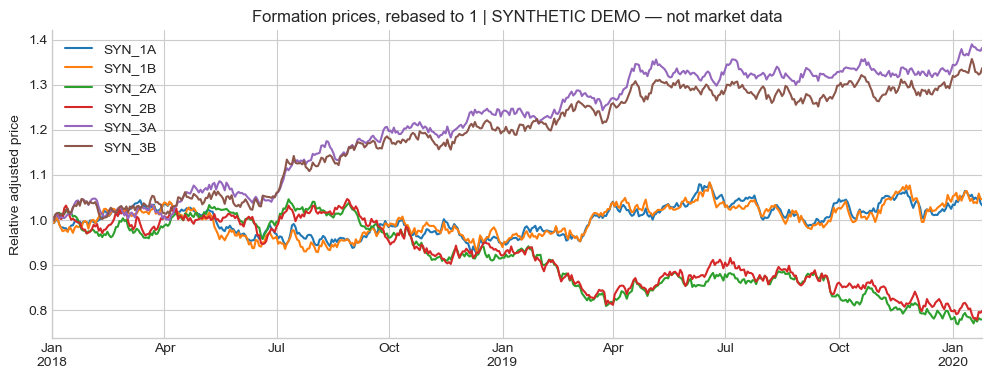

In [4]:
n = len(prices)
formation_end, train_end, validation_end = [int(n * f) for f in (0.30, 0.60, 0.80)]
formation = prices.iloc[:formation_end]
validation_index = prices.index[train_end:validation_end]
test_index = prices.index[validation_end:]
blocks = [("Formation", 0, formation_end), ("ML training", formation_end, train_end),
          ("Validation", train_end, validation_end), ("Test", validation_end, n)]
display(pd.DataFrame([{"block": name, "start": prices.index[a],
                       "end": prices.index[b - 1], "rows": b - a} for name, a, b in blocks]))
ax = (formation / formation.iloc[0]).plot(title=f"Formation prices, rebased to 1 | {DATA_LABEL}")
ax.set_ylabel("Relative adjusted price")
plt.show()


## 4. Select a pair using formation data only

Correlation measures co-movement; cointegration asks whether a linear combination
of integrated price series is stationary. We test all unordered pairs in a fixed
orientation and apply Benjamini–Hochberg false-discovery-rate adjustment across
the full test family. Shared assets make tests dependent, so this is an exploratory
screen rather than a guarantee about false discoveries or future stability.

Return-pattern K-means clusters are displayed as a descriptive aid; they do not
change the testing family. The selection requires positive beta, sufficient
return correlation, and adjusted cointegration p < 0.05. If none qualifies, stop
instead of weakening thresholds. Cointegration presumes appropriate integrated
inputs; inspect individual-series diagnostics and economic rationale for real data.

Reference: [statsmodels cointegration test](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.coint.html).


In [5]:
formation_returns = formation.pct_change(fill_method=None).dropna()
cluster_inputs = ((formation_returns - formation_returns.mean()) /
                  formation_returns.std()).T
if not np.isfinite(cluster_inputs.to_numpy()).all():
    raise ValueError("Constant or invalid return series cannot be clustered.")
clusters = pd.Series(KMeans(n_clusters=min(3, max(1, prices.shape[1] // 2)),
                           random_state=SEED, n_init=10).fit_predict(cluster_inputs),
                     index=formation.columns, name="cluster")
display(clusters.to_frame())

rows = []
for y_name, x_name in combinations(formation.columns, 2):
    fit = sm.OLS(formation[y_name], sm.add_constant(formation[x_name])).fit()
    _, pvalue, _ = coint(formation[y_name], formation[x_name], trend="c", autolag="aic")
    rows.append({"y": y_name, "x": x_name, "correlation": formation_returns[y_name].corr(formation_returns[x_name]),
                 "coint_p": pvalue, "alpha": fit.params.iloc[0], "beta": fit.params.iloc[1]})
pair_table = pd.DataFrame(rows)
pair_table["fdr_p"] = multipletests(pair_table.coint_p.fillna(1), method="fdr_bh")[1]
pair_table["eligible"] = ((pair_table.fdr_p < FDR_ALPHA) & (pair_table.beta > 0) &
                          (pair_table.correlation >= MIN_CORRELATION))
pair_table = pair_table.sort_values(["fdr_p", "coint_p", "y", "x"])
display(pair_table.round(5))
eligible = pair_table.loc[pair_table.eligible]
if eligible.empty:
    raise RuntimeError("No eligible formation pair. Review the universe/data; no backtest was run.")
selected = eligible.iloc[0]
Y, X = selected.y, selected.x
ALPHA, BETA = float(selected.alpha), float(selected.beta)
print(f"Selected: {Y} - ({ALPHA:.4f} + {BETA:.4f} × {X})")


C:\Users\DHEERAJ\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\DHEERAJ\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\DHEERAJ\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\DHEERAJ\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\DHEERAJ\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi

,cluster
SYN_1A,2
SYN_1B,2
SYN_2A,0
SYN_2B,0
SYN_3A,1
SYN_3B,1


,y,x,correlation,coint_p,alpha,beta,fdr_p,eligible
14,SYN_3A,SYN_3B,0.74697,0.00000,-13.86713,0.87391,0.00005,True
9,SYN_2A,SYN_2B,0.75051,0.00001,-7.50401,0.82665,0.00005,True
0,SYN_1A,SYN_1B,0.76783,0.00001,7.41870,0.71427,0.00005,True
5,SYN_1B,SYN_2A,0.03926,0.02092,163.05291,-0.35771,0.07843,False
6,SYN_1B,SYN_2B,0.03194,0.02957,163.70295,-0.27880,0.08870,False
1,SYN_1A,SYN_2A,0.00873,0.06993,122.12729,-0.23641,0.15792,False
2,SYN_1A,SYN_2B,0.00623,0.07868,122.37460,-0.18275,0.15792,False
13,SYN_2B,SYN_3B,0.02317,0.08423,213.00324,-0.60251,0.15792,False
8,SYN_1B,SYN_3B,-0.02682,0.09500,107.99792,0.14405,0.15833,False
7,SYN_1B,SYN_3A,0.01997,0.10825,110.94321,0.15936,0.15953,False


Selected: SYN_3A - (-13.8671 + 0.8739 × SYN_3B)


## 5. Model the spread and rolling Z-score

With formation coefficients frozen, $s_t=P^Y_t-\alpha-\beta P^X_t$.
The Z-score uses the **previous** 60 observations:
$z_t=(s_t-\mu_{t-1})/\sigma_{t-1}$. Today's close is available only after the
close, so any order executes at the next close.

The residual ADF p-value is descriptive: its ordinary critical values do not
account for estimating the residual from prices. The cointegration test above
is the relevant selection test. Half-life comes from an AR(1) fit and is reported
only for a coefficient between zero and one; it is not a promised holding time.


formation_residual_adf_p_descriptive    4.874918e-07
formation_Y_level_adf_p                 7.005983e-01
formation_X_level_adf_p                 6.446457e-01
AR1_phi                                 8.824763e-01
half_life_observations                  5.544141e+00
dtype: float64

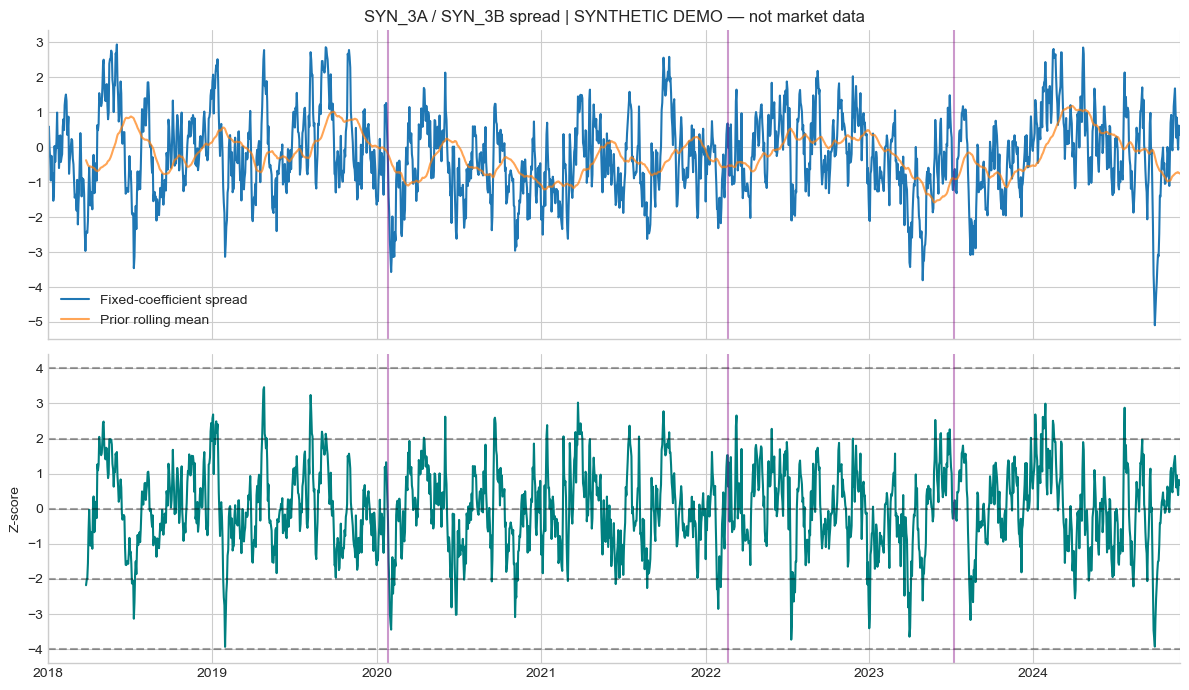

In [6]:
spread = prices[Y] - ALPHA - BETA * prices[X]
prior_mean = spread.shift(1).rolling(LOOKBACK).mean()
prior_std = spread.shift(1).rolling(LOOKBACK).std().replace(0, np.nan)
zscore = ((spread - prior_mean) / prior_std).rename("zscore")
fs = spread.iloc[:formation_end]
ar = sm.OLS(fs.iloc[1:].to_numpy(), sm.add_constant(fs.iloc[:-1].to_numpy())).fit()
phi = float(ar.params[1])
half_life = -np.log(2) / np.log(phi) if 0 < phi < 1 else np.nan
display(pd.Series({"formation_residual_adf_p_descriptive": adfuller(fs, autolag="AIC")[1],
                   "formation_Y_level_adf_p": adfuller(formation[Y], autolag="AIC")[1],
                   "formation_X_level_adf_p": adfuller(formation[X], autolag="AIC")[1],
                   "AR1_phi": phi, "half_life_observations": half_life}))
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
spread.plot(ax=axes[0], label="Fixed-coefficient spread")
prior_mean.plot(ax=axes[0], label="Prior rolling mean", alpha=.7)
axes[0].legend()
zscore.plot(ax=axes[1], color="teal")
for level in [-STOP_Z, -ENTRY_Z, 0, ENTRY_Z, STOP_Z]:
    axes[1].axhline(level, linestyle="--", alpha=.35, color="black")
for ax in axes:
    for boundary in [formation_end, train_end, validation_end]:
        ax.axvline(prices.index[boundary], color="purple", alpha=.4)
axes[0].set_title(f"{Y} / {X} spread | {DATA_LABEL}")
axes[1].set_ylabel("Z-score")
plt.tight_layout()
plt.show()


## 6. Backtest with an explicit execution ledger

When flat, enter long spread below -2 or short spread above +2, but do not enter
beyond |Z| = 4. Exit a long when Z >= -0.5, a short when Z <= +0.5, either when
|Z| >= 4, or after 20 close-to-close holding intervals. Stops are evaluated from
the previous close and are not guaranteed loss limits. No same-close reversal.

A long holds +q shares of Y and -beta*q of X; a short reverses both. At entry,
q is sized so gross notional equals current equity before fees. Shares stay
fixed until exit. This hedges the modeled spread but does not guarantee dollar
or market-beta neutrality. Gross exposure may drift after entry.

At each close: mark yesterday's shares to market, charge borrow on yesterday's
short value over elapsed calendar days, then execute yesterday's signal and
charge fees/slippage on actual traded notional. Force-liquidate on the last
close, with costs. Cash interest, margin funding, taxes, market impact, and
borrow availability are omitted. Adjusted prices approximate total-return P&L;
they are not directly executable share prices around corporate actions.


In [7]:
def backtest(px, z, dates, beta, probabilities=None, threshold=0.0,
             fee_bps=FEE_BPS, slippage_bps=SLIPPAGE_BPS, borrow_rate=BORROW_RATE,
             capital=INITIAL_CAPITAL):
    px = px.loc[dates].iloc[:, :2]
    z = z.reindex(px.index)
    p = (pd.Series(1.0, index=px.index) if probabilities is None
         else probabilities.reindex(px.index))
    if len(px) < 2 or beta <= 0 or capital <= 0:
        raise ValueError("Need two dates, positive beta, and positive capital.")
    unit_cost = (fee_bps + slippage_bps) / 10_000
    shares = np.zeros(2)
    equity, side, age = float(capital), 0, 0
    records, trades = [], []
    entry_date, entry_equity = None, None
    for i, (date, row) in enumerate(px.iterrows()):
        price = row.to_numpy(dtype=float)
        held = shares.copy()
        pnl = borrow = turnover = cost = 0.0
        action, signal_date = "hold", pd.NaT
        if i:
            previous_price = px.iloc[i - 1].to_numpy(dtype=float)
            pnl = float(held @ (price - previous_price))
            days = (date - px.index[i - 1]).days
            borrow = float(np.maximum(-held, 0) @ previous_price) * borrow_rate * days / 365
            equity += pnl - borrow
            if side:
                age += 1
            signal_date = px.index[i - 1]
            signal = z.iloc[i - 1]
            confidence = p.iloc[i - 1]
            reason = None
            if side:
                if i == len(px) - 1:
                    reason = "final liquidation"
                elif not np.isfinite(signal):
                    reason = "missing signal"
                elif abs(signal) >= STOP_Z:
                    reason = "z stop"
                elif age >= MAX_HOLD:
                    reason = "time exit"
                elif (side == 1 and signal >= -EXIT_Z) or (side == -1 and signal <= EXIT_Z):
                    reason = "mean exit"
                if reason:
                    turnover = float(np.abs(shares) @ price)
                    cost = turnover * unit_cost
                    equity -= cost
                    trades.append({"entry_date": entry_date, "exit_date": date,
                                   "side": side, "holding_intervals": age,
                                   "net_pnl": equity - entry_equity, "exit_reason": reason})
                    shares = np.zeros(2)
                    side, age, action = 0, 0, reason
            elif (i < len(px) - 1 and np.isfinite(signal) and
                  ENTRY_Z <= abs(signal) < STOP_Z and np.isfinite(confidence) and
                  confidence >= threshold):
                if equity <= 0:
                    raise RuntimeError("Equity exhausted before entry.")
                side = 1 if signal < 0 else -1
                units = equity / (price[0] + beta * price[1])
                shares = side * units * np.array([1.0, -beta])
                turnover = float(np.abs(shares) @ price)
                cost = turnover * unit_cost
                entry_equity, entry_date = equity, date
                equity -= cost
                age, action = 0, "entry"
        if equity <= 0:
            raise RuntimeError("Equity exhausted; standard return metrics are undefined.")
        records.append({"date": date, "signal_date": signal_date, "equity": equity,
                        "gross_pnl": pnl, "borrow_cost": borrow, "trading_cost": cost,
                        "turnover": turnover, "held_y": held[0], "held_x": held[1],
                        "shares_y": shares[0], "shares_x": shares[1], "side": side,
                        "gross_exposure": float(np.abs(shares) @ price) / equity,
                        "action": action})
    ledger = pd.DataFrame(records).set_index("date")
    ledger["net_return"] = ledger.equity.pct_change(fill_method=None).fillna(0)
    ledger["drawdown"] = ledger.equity / ledger.equity.cummax() - 1
    trade_log = pd.DataFrame(trades, columns=["entry_date", "exit_date", "side",
                                             "holding_intervals", "net_pnl", "exit_reason"])
    return ledger, trade_log


def metrics(ledger, trades):
    r = ledger.net_return.iloc[1:]
    years = (ledger.index[-1] - ledger.index[0]).days / 365.25
    ratio = ledger.equity.iloc[-1] / ledger.equity.iloc[0]
    sharpe = np.sqrt(ANNUALIZATION) * r.mean() / r.std(ddof=1) if r.std(ddof=1) > 0 else np.nan
    return pd.Series({"total_return": ratio - 1, "CAGR": ratio ** (1 / years) - 1,
                      "Sharpe_zero_cash_rate": sharpe,
                      "annualized_volatility": r.std(ddof=1) * np.sqrt(ANNUALIZATION),
                      "max_drawdown": ledger.drawdown.min(), "closed_trades": len(trades),
                      "trade_win_rate": (trades.net_pnl > 0).mean() if len(trades) else np.nan,
                      "fraction_intervals_in_market": (ledger.held_y.iloc[1:] != 0).mean(),
                      "trading_cost_dollars": ledger.trading_cost.sum(),
                      "borrow_cost_dollars": ledger.borrow_cost.sum()})


pair_prices = prices[[Y, X]]
validation_baseline, validation_baseline_trades = backtest(pair_prices, zscore, validation_index, BETA)
display(metrics(validation_baseline, validation_baseline_trades).to_frame("Validation baseline"))


,Validation baseline
total_return,0.035666
CAGR,0.025879
Sharpe_zero_cash_rate,1.688063
annualized_volatility,0.014637
max_drawdown,-0.007029
closed_trades,10.000000
trade_win_rate,0.900000
fraction_intervals_in_market,0.167131
trading_cost_dollars,1011.670864
borrow_cost_dollars,235.341248


## 7. Train an ML entry filter without crossing the split boundary

The classifier estimates whether the proposed mean-reversion direction produces
positive net P&L over five intervals **after next-close execution**. The label
uses fixed one-Y / beta-X shares and deducts both-leg round-trip costs plus
estimated borrow. It is a fixed-horizon proxy; actual trades use the exits above.

Features are known at signal time: Z-score, spread changes/volatility, return
correlation, and relative volume. Only candidate-entry days train the model.
Every training label must finish before validation begins. Overlapping training
labels remain dependent; we do not use random cross-validation or interpret
training accuracy as evidence. Model hyperparameters are fixed in advance.

Reference: [scikit-learn time-series evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split).


In [8]:
def make_features(px, vol, spread_series, z):
    r = px.pct_change(fill_method=None)
    relative_volume = vol / vol.shift(1).rolling(20, min_periods=10).median()
    relative_volume = relative_volume.replace([np.inf, -np.inf], np.nan).fillna(1.0)
    f = pd.DataFrame({"z": z, "abs_z": z.abs(), "z_change": z.diff(),
                      "spread_change": spread_series.diff(),
                      "spread_momentum_5": spread_series.diff(5),
                      "spread_volatility_20": spread_series.diff().rolling(20).std(),
                      "return_correlation_60": r.iloc[:, 0].rolling(60).corr(r.iloc[:, 1]),
                      "relative_volume_y": relative_volume.iloc[:, 0],
                      "relative_volume_x": relative_volume.iloc[:, 1]})
    return f.replace([np.inf, -np.inf], np.nan)


features = make_features(pair_prices, volumes[[Y, X]], spread, zscore)
direction = -np.sign(zscore)
future_entry = pair_prices.shift(-1)
future_exit = pair_prices.shift(-(LABEL_HORIZON + 1))
label_gross = direction * (future_exit[Y] - future_entry[Y] - BETA * (future_exit[X] - future_entry[X]))
label_cost = ((future_entry[Y] + future_exit[Y]) + BETA * (future_entry[X] + future_exit[X])) * (FEE_BPS + SLIPPAGE_BPS) / 10_000
# Exact daily short notional for the fixed-horizon, one-unit label trade.
day_gaps = prices.index.to_series().diff().dt.days
label_borrow = pd.Series(0.0, index=prices.index)
for step in range(1, LABEL_HORIZON + 1):
    mark = pair_prices.shift(-step)
    short_value = pd.Series(np.where(direction > 0, BETA * mark[X], mark[Y]), index=prices.index)
    label_borrow += short_value * BORROW_RATE * day_gaps.shift(-(step + 1)) / 365
label_net = label_gross - label_cost - label_borrow
label_end = prices.index.to_series().shift(-(LABEL_HORIZON + 1))
labels = (label_net > 0).astype(float).where(label_net.notna())
candidate = zscore.abs().ge(ENTRY_Z) & zscore.abs().lt(STOP_Z)
complete = features.notna().all(axis=1)
train_mask = ((prices.index >= prices.index[formation_end]) &
              (prices.index < prices.index[train_end]) &
              (label_end < prices.index[train_end]) & candidate & complete & labels.notna())
if train_mask.sum() < 30 or labels[train_mask].nunique() < 2:
    raise RuntimeError("Too few labeled entry examples or only one class; ML comparison is not supported.")
model = RandomForestClassifier(n_estimators=200, max_depth=3, min_samples_leaf=8,
                               class_weight="balanced", random_state=SEED, n_jobs=1)
model.fit(features.loc[train_mask], labels.loc[train_mask].astype(int))
probabilities = pd.Series(np.nan, index=prices.index, name="entry_probability")
positive_class = list(model.classes_).index(1)
probabilities.loc[complete] = model.predict_proba(features.loc[complete])[:, positive_class]
assert label_end.loc[train_mask].max() < validation_index[0]
print(f"Training entry examples: {train_mask.sum()}; positive fraction: {labels[train_mask].mean():.1%}")
display(pd.Series(model.feature_importances_, index=features.columns,
                   name="Training feature importance").sort_values(ascending=False))


Training entry examples: 48; positive fraction: 75.0%


abs_z                    0.197114
spread_volatility_20     0.136568
z_change                 0.119794
z                        0.113776
return_correlation_60    0.109887
spread_momentum_5        0.102799
relative_volume_y        0.089430
spread_change            0.077913
relative_volume_x        0.052718
Name: Training feature importance, dtype: float64

## 8. Choose the probability threshold on validation only

Compare a small preset threshold grid, requiring at least three closed validation
trades. Choose the highest validation Sharpe; ties favor the lower threshold.
A zero threshold means retain the baseline entry rule. If no candidate has
enough trades, use the baseline rule and report that choice. Threshold search
itself can overfit this single validation block.


In [9]:
threshold_rows = []
for threshold in [0.0, 0.45, 0.50, 0.55, 0.60, 0.65]:
    ledger, trades = backtest(pair_prices, zscore, validation_index, BETA,
                              None if threshold == 0 else probabilities, threshold)
    m = metrics(ledger, trades)
    threshold_rows.append({"threshold": threshold, "Sharpe": m.Sharpe_zero_cash_rate,
                           "return": m.total_return, "trades": int(m.closed_trades)})
threshold_table = pd.DataFrame(threshold_rows)
valid_thresholds = threshold_table[(threshold_table.trades >= 3) & np.isfinite(threshold_table.Sharpe)]
CHOSEN_THRESHOLD = (float(valid_thresholds.sort_values(["Sharpe", "threshold"], ascending=[False, True]).iloc[0].threshold)
                    if len(valid_thresholds) else 0.0)
display(threshold_table)
print(f"Frozen threshold: {CHOSEN_THRESHOLD:.2f}")
if CHOSEN_THRESHOLD == 0:
    print("Validation retained the baseline entry rule; ML filtering is disabled for the test.")


,threshold,Sharpe,return,trades
0,0.00,1.688063,0.035666,10
1,0.45,1.688063,0.035666,10
2,0.50,1.234064,0.023112,7
3,0.55,1.023786,0.014120,5
4,0.60,1.262154,0.013419,3
5,0.65,0.871986,0.004582,1


Frozen threshold: 0.00
Validation retained the baseline entry rule; ML filtering is disabled for the test.


## 9. Evaluate the untouched test block

Both strategies start flat with the same capital and the same costs. The model
is not retrained after threshold selection. Sharpe uses daily net returns, a
zero cash benchmark, and sqrt(252); dependence can make it misleading. Drawdown
includes the starting capital and all costs. Win rate uses closed-trade net P&L.
The test may favor the baseline or produce no ML trades; neither outcome is hidden.


HELD-OUT RESULTS | SYNTHETIC DEMO — not market data


,Z-score baseline,Validation-selected rule
total_return,0.0398,0.0398
CAGR,0.0289,0.0289
Sharpe_zero_cash_rate,1.8201,1.8201
annualized_volatility,0.0151,0.0151
max_drawdown,-0.0090,-0.0090
closed_trades,10.0000,10.0000
trade_win_rate,0.8000,0.8000
fraction_intervals_in_market,0.2173,0.2173
trading_cost_dollars,1010.8106,1010.8106
borrow_cost_dollars,295.9893,295.9893


Test candidate count: 35; Brier score: 0.249
Test ROC AUC: 0.39


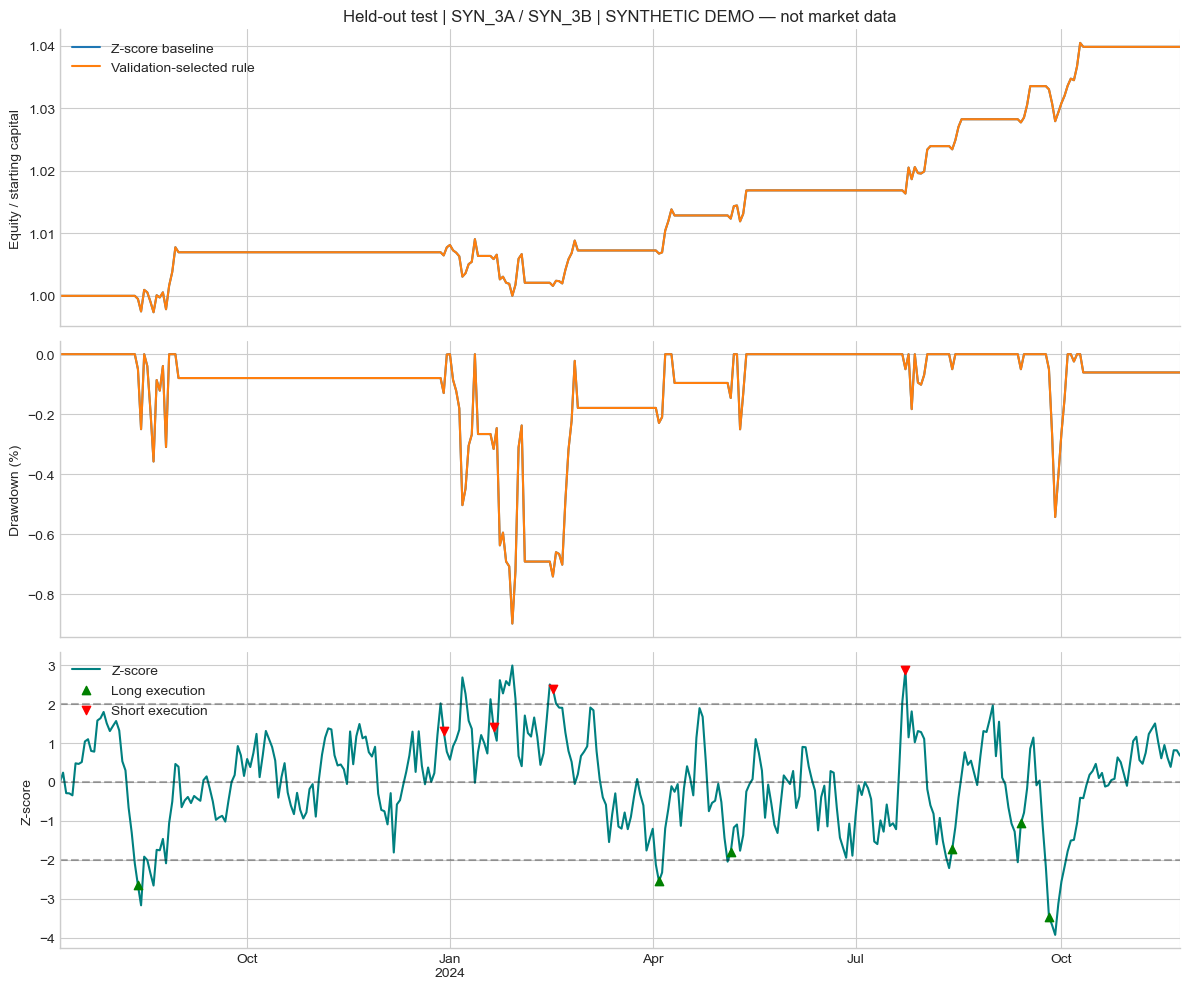

,entry_date,exit_date,side,holding_intervals,net_pnl,exit_reason
0,2023-08-14,2023-08-31,1,13,696.452883,mean exit
1,2023-12-28,2024-01-12,-1,11,-58.956317,mean exit
2,2024-01-19,2024-02-02,-1,10,-428.602412,mean exit
3,2024-02-15,2024-02-27,-1,8,516.267655,mean exit
4,2024-04-03,2024-04-10,1,5,559.469970,mean exit
5,2024-05-06,2024-05-14,1,6,400.867253,mean exit
6,2024-07-23,2024-08-02,-1,8,706.804783,mean exit
7,2024-08-13,2024-08-16,1,3,429.954818,mean exit
8,2024-09-12,2024-09-17,1,3,528.835060,mean exit
9,2024-09-25,2024-10-10,1,11,627.973153,mean exit


In [10]:
baseline, baseline_trades = backtest(pair_prices, zscore, test_index, BETA)
filtered, filtered_trades = backtest(pair_prices, zscore, test_index, BETA,
                                    None if CHOSEN_THRESHOLD == 0 else probabilities,
                                    CHOSEN_THRESHOLD)
comparison = pd.DataFrame({"Z-score baseline": metrics(baseline, baseline_trades),
                           "Validation-selected rule": metrics(filtered, filtered_trades)})
print(f"HELD-OUT RESULTS | {DATA_LABEL}")
display(comparison.round(4))
test_label_mask = ((prices.index >= test_index[0]) & candidate & complete & labels.notna() &
                   (label_end <= test_index[-1]))
if test_label_mask.any():
    actual = labels.loc[test_label_mask]
    predicted = probabilities.loc[test_label_mask]
    print(f"Test candidate count: {len(actual)}; Brier score: {brier_score_loss(actual, predicted):.3f}")
    print("Test ROC AUC:", round(roc_auc_score(actual, predicted), 3) if actual.nunique() == 2 else "undefined: one class")

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for name, ledger in [("Z-score baseline", baseline), ("Validation-selected rule", filtered)]:
    (ledger.equity / INITIAL_CAPITAL).plot(ax=axes[0], label=name)
    (100 * ledger.drawdown).plot(ax=axes[1], label=name)
zscore.loc[test_index].plot(ax=axes[2], color="teal", label="Z-score")
for side, marker, color in [(1, "^", "green"), (-1, "v", "red")]:
    dates = baseline.index[(baseline.action == "entry") & (baseline.side == side)]
    axes[2].scatter(dates, zscore.loc[dates], marker=marker, color=color,
                    label="Long execution" if side == 1 else "Short execution", zorder=3)
for level in [-ENTRY_Z, 0, ENTRY_Z]:
    axes[2].axhline(level, color="black", linestyle="--", alpha=.3)
axes[0].set_title(f"Held-out test | {Y} / {X} | {DATA_LABEL}")
axes[0].set_ylabel("Equity / starting capital")
axes[1].set_ylabel("Drawdown (%)")
axes[2].set_ylabel("Z-score")
axes[0].legend(); axes[2].legend(loc="upper left")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "test_results.png", dpi=160, bbox_inches="tight")
plt.show()
display(filtered_trades.head(10))


## 10. Cost sensitivity and accounting checks

The sensitivity table holds all selected parameters fixed and varies slippage
only. It is a test-period stress report, not another optimization step. The
assertions reconcile equity to P&L and costs, check final liquidation, and verify
that each execution references an earlier signal date.


In [11]:
stress_rows = []
for slippage in sorted(set([0.0, SLIPPAGE_BPS, 10.0, 20.0])):
    ledger, trades = backtest(pair_prices, zscore, test_index, BETA,
                              None if CHOSEN_THRESHOLD == 0 else probabilities,
                              CHOSEN_THRESHOLD, slippage_bps=slippage)
    stress_rows.append({"slippage_bps_per_leg": slippage,
                        "return": metrics(ledger, trades).total_return,
                        "net_profit": ledger.equity.iloc[-1] - INITIAL_CAPITAL})
stress = pd.DataFrame(stress_rows)
display(stress)
for ledger, trades in [(baseline, baseline_trades), (filtered, filtered_trades)]:
    expected = INITIAL_CAPITAL + (ledger.gross_pnl - ledger.borrow_cost - ledger.trading_cost).cumsum()
    np.testing.assert_allclose(ledger.equity, expected, atol=1e-7)
    np.testing.assert_allclose(trades.net_pnl.sum(), ledger.equity.iloc[-1] - INITIAL_CAPITAL, atol=1e-7)
    assert ledger.iloc[-1].shares_y == ledger.iloc[-1].shares_x == 0
    executions = ledger.loc[ledger.turnover > 0]
    assert (executions.signal_date < executions.index).all()
assert np.isfinite(comparison.loc[["total_return", "max_drawdown"]].to_numpy()).all()
print("Accounting and chronological execution checks passed.")


,slippage_bps_per_leg,return,net_profit
0,0.0,0.048082,4808.189837
1,4.0,0.039791,3979.066846
2,10.0,0.027464,2746.447818
3,20.0,0.007213,721.279678


Accounting and chronological execution checks passed.


## 11. Save research artifacts and interpret the result

Exports include aligned inputs, the pair screen, run parameters, package versions,
daily positions/P&L, trades, metrics, and the test chart. These preserve the
selected run for review. The directory is overwritten on rerun.

Before drawing conclusions from real data, investigate economic linkage,
survivorship bias, structural breaks, trading calendars, available borrow, and
corporate actions. A broader study should use repeated forward-moving formation
and test windows, selection-aware inference, and realistic execution data.
Dollar neutrality and market-beta neutrality require separate risk constraints.

Documentation: [ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html),
[cointegration](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.coint.html),
[chronological evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split),
[yfinance download](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).


In [12]:
prices.to_csv(OUTPUT_DIR / "aligned_prices.csv", index_label="Date")
volumes.to_csv(OUTPUT_DIR / "aligned_volumes.csv", index_label="Date")
pair_table.to_csv(OUTPUT_DIR / "pair_screen.csv", index=False)
comparison.to_csv(OUTPUT_DIR / "test_metrics.csv")
threshold_table.to_csv(OUTPUT_DIR / "validation_thresholds.csv", index=False)
stress.to_csv(OUTPUT_DIR / "cost_sensitivity.csv", index=False)
for name, ledger, trades in [("baseline", baseline, baseline_trades), ("selected", filtered, filtered_trades)]:
    ledger.to_csv(OUTPUT_DIR / f"{name}_test_ledger.csv")
    trades.to_csv(OUTPUT_DIR / f"{name}_test_trades.csv", index=False)
packages = ["numpy", "pandas", "matplotlib", "scipy", "statsmodels", "scikit-learn"]
config = {"data_source": DATA_SOURCE, "seed": SEED, "pair": [Y, X], "alpha": ALPHA, "beta": BETA,
          "lookback": LOOKBACK, "entry_z": ENTRY_Z, "exit_z": EXIT_Z, "stop_z": STOP_Z,
          "max_hold": MAX_HOLD, "label_horizon": LABEL_HORIZON, "capital": INITIAL_CAPITAL,
          "fee_bps": FEE_BPS, "slippage_bps": SLIPPAGE_BPS, "borrow_rate": BORROW_RATE,
          "minimum_correlation": MIN_CORRELATION, "fdr_alpha": FDR_ALPHA,
          "threshold": CHOSEN_THRESHOLD, "execution": "signal close t; fill close t+1",
          "blocks": [{"name": name, "start": str(prices.index[a].date()),
                      "end": str(prices.index[b - 1].date())} for name, a, b in blocks],
          "python": platform.python_version(),
          "packages": {name: importlib.metadata.version(name) for name in packages},
          "model_parameters": model.get_params()}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"Saved research artifacts to {OUTPUT_DIR.resolve()}")


Saved research artifacts to C:\Users\DHEERAJ\OneDrive\Desktop\pairs trading\outputs
